# DIP Assignment 2 — Question 1

## DFT and the Machinery of Frequency

This notebook addresses every sub-question in Sections 1.1, 1.2, and 1.3 of the official Digital Image Processing Assignment 2. It uses the supplied `A2/Q1,4/q1.png` image and implements the required transforms and convolution operations with NumPy array arithmetic.

**Reproducibility:** run all cells from a clean kernel. Figures are written to `outputs/Q1/figures/` and machine-readable tables to `outputs/Q1/tables/`.


## Objectives and conventions

For an image `f[y, x]`, `x` is the column index and `y` is the row index. The forward transform is

\[
F[v,u]=\sum_{y=0}^{N-1}\sum_{x=0}^{N-1}f[y,x]e^{-j2\pi(ux+vy)/N}.
\]

With \(W_N[k,n]=e^{-j2\pi kn/N}\), row-column separability gives `F = W_N @ f @ W_N.T`; the inverse is
`f = (W_N.conj().T @ F @ W_N.conj()) / N**2`. `fftshift` is used only to center a visualization, never to modify coefficients before inversion.

The direct matrix DFT costs \(O(N^3)\) for an \(N\times N\) image, whereas an FFT costs \(O(N^2\log N)\).

### Numerical tolerance policy

The notebook reports both absolute and relative errors. Direct matrix products can accumulate absolute errors of a few \(10^{-6}\) in very large Fourier coefficients even when the relative error is around \(10^{-13}\). Therefore:

- `ABS_COMPLEX_TOL = 1e-5` is used for maximum complex-coefficient errors.
- `REL_TOL = 1e-10` is used for relative L2 errors.
- `REAL_RECON_TOL = 1e-8` is used for inverse, convolution, and phase/magnitude residuals.
- `PHASE_TOL = 1e-6` is used for recovered sinusoid phase.

These are numerical tolerances, not claims of exact equality.


Python: 3.13.14
NumPy: 2.2.6
Operating system: Windows-11-10.0.26300-SP0
CPU: 13th Gen Intel(R) Core(TM) i7-13700HX
Total RAM (GiB): 15.726
Image path: D:\College\IIITH\DIP\Assignment-2\DIP_A2\A2\Q1,4\q1.png
Image shape: (512, 512) dtype: uint8 min: 0 max: 255 dynamic range: 255


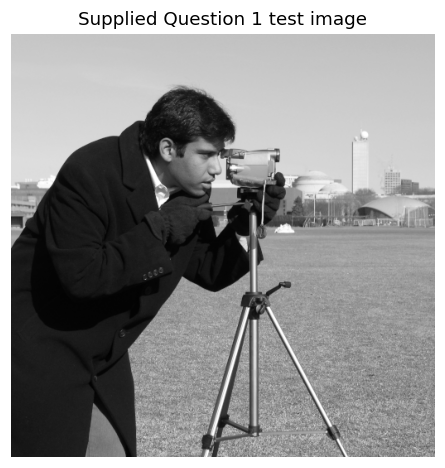

In [1]:
import csv
import os
import platform
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

np.set_printoptions(precision=6, suppress=True)
plt.rcParams["figure.dpi"] = 110
ROOT = Path.cwd()
if not (ROOT / "A2").exists():
    candidates = list(ROOT.rglob("q1.png"))
    if not candidates:
        raise FileNotFoundError("Could not locate the supplied q1.png image.")
    IMAGE_PATH = candidates[0]
else:
    IMAGE_PATH = ROOT / "A2" / "Q1,4" / "q1.png"
OUT = ROOT / "outputs" / "Q1"
FIG = OUT / "figures"
TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Operating system:", platform.platform())
def exact_cpu_model():
    try:
        return subprocess.check_output(
            ["powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor | Select-Object -First 1 -ExpandProperty Name)"],
            text=True,
            stderr=subprocess.DEVNULL,
        ).strip() or platform.processor() or "Not reported"
    except (OSError, subprocess.SubprocessError):
        return platform.processor() or "Not reported"

print("CPU:", exact_cpu_model())
try:
    import psutil
    print("Total RAM (GiB):", round(psutil.virtual_memory().total / 2**30, 3))
except ImportError as exc:
    raise RuntimeError("psutil is required to report total RAM accurately.") from exc
print("Image path:", IMAGE_PATH)
image = np.asarray(Image.open(IMAGE_PATH).convert("L"))
if image.shape != (512, 512) or image.dtype != np.uint8:
    raise ValueError(f"Expected a 512x512 uint8 grayscale image, got {image.shape} {image.dtype}.")
image_f = image.astype(np.float64)
print("Image shape:", image.shape, "dtype:", image.dtype,
      "min:", image.min(), "max:", image.max(), "dynamic range:", int(image.max()-image.min()))

def savefig(name):
    path = FIG / name
    plt.savefig(path, bbox_inches="tight", dpi=150)
    return path

def write_rows(name, fieldnames, rows):
    with open(TAB / name, "w", newline="", encoding="utf-8") as fh:
        writer = csv.DictWriter(fh, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Supplied Question 1 test image")
plt.axis("off")
savefig("01_original.png")
plt.show()


## Section 1.1 — Matrix DFT implementation and validation

The negative exponent is the forward-DFT convention used by NumPy. The inverse uses the conjugate-transposed DFT matrix and a factor of \(1/N^2\) in two dimensions.


Custom DFT elapsed seconds: 0.057
DFT verification: {'maximum absolute error': 3.3704750409373667e-06, 'mean absolute error': 1.2767628418235578e-09, 'relative L2 error': 1.3467218559736226e-13}
Inverse verification: {'maximum absolute reconstruction error': 7.212008767965017e-11, 'mean absolute reconstruction error': 1.1087719962001377e-11, 'relative L2 reconstruction error': 9.347252698516512e-14, 'maximum absolute imaginary residual': 5.510969458555337e-11}


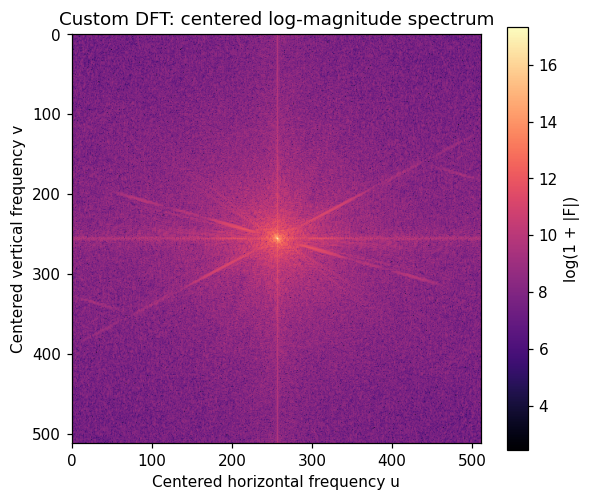

In [2]:
def dft_matrix(N):
    """Return W_N[k,n] = exp(-2 pi j k n / N) using array arithmetic."""
    k = np.arange(N)[:, None]
    n = np.arange(N)[None, :]
    return np.exp(-2j * np.pi * k * n / N)

def dft2_custom(arr):
    arr = np.asarray(arr)
    if arr.ndim != 2 or arr.shape[0] != arr.shape[1]:
        raise ValueError("dft2_custom requires a square two-dimensional array.")
    n = arr.shape[0]
    W = dft_matrix(n)
    return W @ arr.astype(np.complex128) @ W.T

def idft2_custom(F):
    F = np.asarray(F)
    if F.ndim != 2 or F.shape[0] != F.shape[1]:
        raise ValueError("idft2_custom requires a square two-dimensional spectrum.")
    n = F.shape[0]
    W = dft_matrix(n)
    return (W.conj().T @ F.astype(np.complex128) @ W.conj()) / (n*n)

def dft2_rect_custom(arr):
    """Rectangular 2-D DFT, used for the required Npad x Npad experiment."""
    arr = np.asarray(arr)
    ny, nx = arr.shape
    Wy, Wx = dft_matrix(ny), dft_matrix(nx)
    return Wy @ arr.astype(np.complex128) @ Wx.T

def idft2_rect_custom(F):
    ny, nx = F.shape
    Wy, Wx = dft_matrix(ny), dft_matrix(nx)
    return (Wy.conj().T @ F.astype(np.complex128) @ Wx.conj()) / (ny*nx)

ABS_COMPLEX_TOL = 1e-5
REL_TOL = 1e-10
REAL_RECON_TOL = 1e-8
PHASE_TOL = 1e-6

t0 = time.perf_counter()
F_custom = dft2_custom(image_f)
F_numpy = np.fft.fft2(image_f)
inverse_custom = idft2_custom(F_custom)
custom_fft_err = F_custom - F_numpy
fft_metrics = {
    "maximum absolute error": float(np.max(np.abs(custom_fft_err))),
    "mean absolute error": float(np.mean(np.abs(custom_fft_err))),
    "relative L2 error": float(np.linalg.norm(custom_fft_err) / np.linalg.norm(F_numpy)),
}
recon_err = inverse_custom.real - image_f
inverse_metrics = {
    "maximum absolute reconstruction error": float(np.max(np.abs(recon_err))),
    "mean absolute reconstruction error": float(np.mean(np.abs(recon_err))),
    "relative L2 reconstruction error": float(np.linalg.norm(recon_err) / np.linalg.norm(image_f)),
    "maximum absolute imaginary residual": float(np.max(np.abs(inverse_custom.imag))),
}
print("Custom DFT elapsed seconds:", round(time.perf_counter()-t0, 3))
print("DFT verification:", fft_metrics)
print("Inverse verification:", inverse_metrics)
fft_tolerances = {
    "maximum absolute error": ABS_COMPLEX_TOL,
    "mean absolute error": ABS_COMPLEX_TOL,
    "relative L2 error": REL_TOL,
}
write_rows("01_dft_verification.csv", ["metric", "value", "tolerance", "pass"],
           [{"metric": k, "value": v, "tolerance": fft_tolerances[k],
             "pass": v <= fft_tolerances[k]} for k, v in fft_metrics.items()])
inverse_tolerances = {
    "maximum absolute reconstruction error": REAL_RECON_TOL,
    "mean absolute reconstruction error": REAL_RECON_TOL,
    "relative L2 reconstruction error": REL_TOL,
    "maximum absolute imaginary residual": REAL_RECON_TOL,
}
write_rows("02_inverse_verification.csv", ["metric", "value", "tolerance", "pass"],
           [{"metric": k, "value": v, "tolerance": inverse_tolerances[k],
             "pass": v <= inverse_tolerances[k]} for k, v in inverse_metrics.items()])

plt.figure(figsize=(6, 5))
plt.imshow(np.log1p(np.abs(np.fft.fftshift(F_custom))), cmap="magma")
plt.colorbar(label="log(1 + |F|)")
plt.title("Custom DFT: centered log-magnitude spectrum")
plt.xlabel("Centered horizontal frequency u")
plt.ylabel("Centered vertical frequency v")
savefig("02_custom_dft_spectrum.png")
plt.show()


### 1.1(a) Conjugate symmetry proof

For real `f[x,y]`, take the complex conjugate of the DFT:

\[
F^*[u,v]=\sum_{x,y}f[x,y]e^{+j2\pi(ux+vy)/N}
 =\sum_{x,y}f[x,y]e^{-j2\pi((-u)x+(-v)y)/N}
 =F[(-u)\bmod N,(-v)\bmod N].
\]

Thus coefficients occur in conjugate pairs and their magnitudes are equal. DC is self-conjugate; for even `N`, coefficients on the Nyquist axes and at the Nyquist corner can also be self-conjugate. One representative of every pair is sufficient for a real reconstruction, but visualizers show the complete spectrum so spatial orientation and all frequency locations remain visible.


{'maximum complex conjugate-symmetry error': 3.375383607360116e-06, 'mean complex conjugate-symmetry error': 2.141903335211706e-09, 'maximum magnitude-symmetry error': 1.7853453755378723e-06}


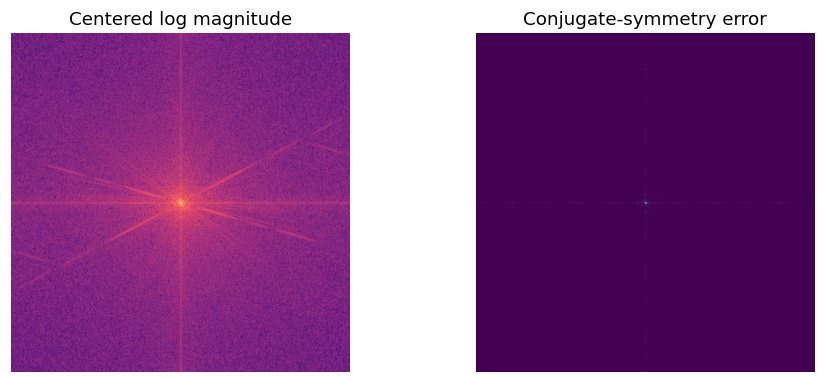

In [3]:
N = image_f.shape[0]
rows = np.arange(N)[:, None]
cols = np.arange(N)[None, :]
F_partner = F_custom[(-rows) % N, (-cols) % N]
symmetry_error = F_custom - np.conj(F_partner)
magnitude_symmetry_error = np.abs(np.abs(F_custom) - np.abs(F_partner))
symmetry_metrics = {
    "maximum complex conjugate-symmetry error": float(np.max(np.abs(symmetry_error))),
    "mean complex conjugate-symmetry error": float(np.mean(np.abs(symmetry_error))),
    "maximum magnitude-symmetry error": float(np.max(magnitude_symmetry_error)),
}
symmetry_tolerances = {
    "maximum complex conjugate-symmetry error": ABS_COMPLEX_TOL,
    "mean complex conjugate-symmetry error": ABS_COMPLEX_TOL,
    "maximum magnitude-symmetry error": ABS_COMPLEX_TOL,
}
print(symmetry_metrics)
write_rows("03_conjugate_symmetry.csv", ["metric", "value", "tolerance", "pass"],
           [{"metric": k, "value": v, "tolerance": symmetry_tolerances[k],
             "pass": v <= symmetry_tolerances[k]} for k, v in symmetry_metrics.items()])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(np.log1p(np.abs(np.fft.fftshift(F_custom))), cmap="magma")
ax[0].set_title("Centered log magnitude")
ax[1].imshow(np.abs(np.fft.fftshift(symmetry_error)), cmap="viridis")
ax[1].set_title("Conjugate-symmetry error")
for a in ax: a.axis("off")
savefig("03_conjugate_symmetry.png")
plt.show()


### 1.1(b) Shift theorem and circular-convolution theorem

For `shifted = roll(image, (dy, dx))`, the convention is

\[
F_s[v,u]=F[v,u]e^{-j2\pi(u\,dx+v\,dy)/N}.
\]

Circular convolution is implemented explicitly as
`sum(kernel[i,j] * roll(image, (i,j)))`, so it matches multiplication of the DFT of the image and the origin-placed kernel. This is convolution, not correlation: the kernel is not implicitly conjugated or reversed.


Shift theorem table: [{'dx': 13, 'dy': 7, 'maximum absolute error': 1.923131171143729e-06, 'mean absolute error': 1.2823657383964765e-09, 'relative L2 error': 1.1065065723532583e-13, 'absolute tolerance': 1e-05, 'relative tolerance': 1e-10, 'pass': True}, {'dx': -16, 'dy': 11, 'maximum absolute error': 2.0694141407749188e-06, 'mean absolute error': 1.3159786035478804e-09, 'relative L2 error': 1.1303518707992286e-13, 'absolute tolerance': 1e-05, 'relative tolerance': 1e-10, 'pass': True}]
Circular convolution theorem: {'maximum absolute error': 7.708478300116894e-11, 'mean absolute error': 1.2121850264513016e-11, 'relative L2 error': 4.445380153519967e-13}


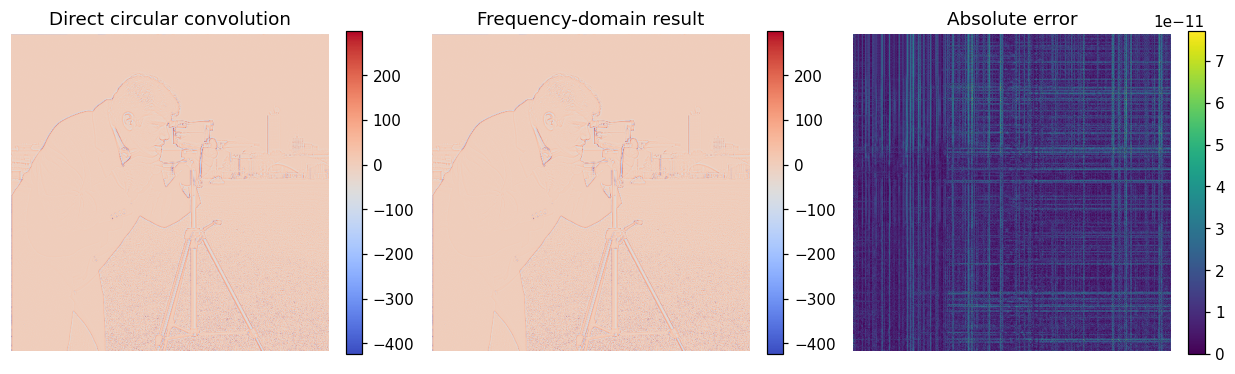

In [4]:
def metric_dict(actual, expected):
    e = np.asarray(actual) - np.asarray(expected)
    return {"maximum absolute error": float(np.max(np.abs(e))),
            "mean absolute error": float(np.mean(np.abs(e))),
            "relative L2 error": float(np.linalg.norm(e) / max(np.linalg.norm(expected), 1e-15))}, e

shift_rows = []
for dx, dy in [(13, 7), (-16, 11)]:
    shifted = np.roll(image_f, (dy, dx), axis=(0, 1))
    F_shifted = dft2_custom(shifted)
    u = np.arange(N)[None, :]
    v = np.arange(N)[:, None]
    prediction = F_custom * np.exp(-2j*np.pi*(u*dx + v*dy)/N)
    m, _ = metric_dict(F_shifted, prediction)
    shift_rows.append({"dx": dx, "dy": dy, **m,
                       "absolute tolerance": ABS_COMPLEX_TOL,
                       "relative tolerance": REL_TOL,
                       "pass": m["maximum absolute error"] <= ABS_COMPLEX_TOL and m["relative L2 error"] <= REL_TOL})
print("Shift theorem table:", shift_rows)
write_rows("04_shift_theorem.csv",
           ["dx","dy","maximum absolute error","mean absolute error","relative L2 error",
            "absolute tolerance","relative tolerance","pass"], shift_rows)

kernel3 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float64)
def circular_convolution(image_arr, kernel):
    result = np.zeros_like(image_arr, dtype=np.float64)
    for i in range(kernel.shape[0]):
        for j in range(kernel.shape[1]):
            result += kernel[i, j] * np.roll(image_arr, (i, j), axis=(0, 1))
    return result

kernel_origin = np.zeros_like(image_f)
kernel_origin[:3, :3] = kernel3
conv_spatial = circular_convolution(image_f, kernel3)
conv_frequency = idft2_custom(dft2_custom(image_f) * dft2_custom(kernel_origin)).real
conv_metrics, conv_error = metric_dict(conv_spatial, conv_frequency)
print("Circular convolution theorem:", conv_metrics)
write_rows("05_circular_convolution.csv",
           ["metric","value","tolerance","pass"],
           [{"metric": k, "value": v, "tolerance": REAL_RECON_TOL,
             "pass": v <= REAL_RECON_TOL} for k,v in conv_metrics.items()])
coords = [(0,0), (10,10), (256,256), (511,511)]
write_rows("05_circular_convolution_samples.csv",
           ["row","column","spatial","frequency","absolute error"],
           [{"row": y, "column": x, "spatial": conv_spatial[y,x], "frequency": conv_frequency[y,x],
             "absolute error": abs(conv_spatial[y,x]-conv_frequency[y,x])} for y,x in coords])
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, z, title in zip(ax, [conv_spatial, conv_frequency, np.abs(conv_error)],
                       ["Direct circular convolution", "Frequency-domain result", "Absolute error"]):
    im = a.imshow(z, cmap="coolwarm" if title != "Absolute error" else "viridis")
    a.set_title(title); a.axis("off"); fig.colorbar(im, ax=a, fraction=.046)
savefig("04_circular_convolution.png")
plt.show()


### 1.1(c) Synthetic sinusoid parameter recovery

The synthetic image is
\[
f[x,y]=\sum_i A_i\cos(2\pi(u_i x+v_i y)/N+\phi_i).
\]
For an integer-bin cosine with no overlapping components,
\[
\cos(\theta+\phi)=\tfrac12e^{j(\theta+\phi)}+\tfrac12e^{-j(\theta+\phi)}.
\]
Therefore the positive-bin coefficient is \(F[v_i,u_i]=(A_iN^2/2)e^{j\phi_i}\), giving
\[
A_i=2|F[v_i,u_i]|/N^2,\qquad \phi_i=\arg F[v_i,u_i].
\]
The negative-frequency coefficient is its conjugate at `((-u_i) mod N, (-v_i) mod N)`.

The recovery below detects spectral peaks from `|F_syn|` alone. It does not read the known bins as the recovered answer: a greedy non-maximum-suppression detector selects the six largest separated peaks after masking the DC neighborhood, then the three detected peaks in the first half of the DFT index grid are used as positive-frequency representatives. Ground truth is used only afterward to label the comparison and calculate recovery error.

The DFT grid spacing is 1 cycle per image width (or height), equivalently `1/N` cycles per pixel. Off-bin frequencies would spread energy across neighboring bins and make peak-based amplitude/phase recovery less exact.


Detected peaks (u,v): [(np.int64(13), np.int64(7)), (np.int64(499), np.int64(505)), (np.int64(31), np.int64(19)), (np.int64(481), np.int64(493)), (np.int64(45), np.int64(53)), (np.int64(467), np.int64(459))]
Recovered sinusoid parameters: [{'component': 1, 'ground truth frequency': '(13,7)', 'detected positive frequency': '(13,7)', 'frequency error': 0.0, 'ground truth amplitude': 80.0, 'recovered amplitude': np.float64(80.0), 'amplitude error': np.float64(0.0), 'ground truth phase': 0.35, 'recovered phase': np.float64(0.3499999999999943), 'wrapped phase error': np.float64(-5.662137425588298e-15)}, {'component': 2, 'ground truth frequency': '(31,19)', 'detected positive frequency': '(31,19)', 'frequency error': 0.0, 'ground truth amplitude': 50.0, 'recovered amplitude': np.float64(50.00000000000002), 'amplitude error': np.float64(2.1316282072803006e-14), 'ground truth phase': -1.1, 'recovered phase': np.float64(-1.09999999999999), 'wrapped phase error': np.float64(9.992007221626409e-15

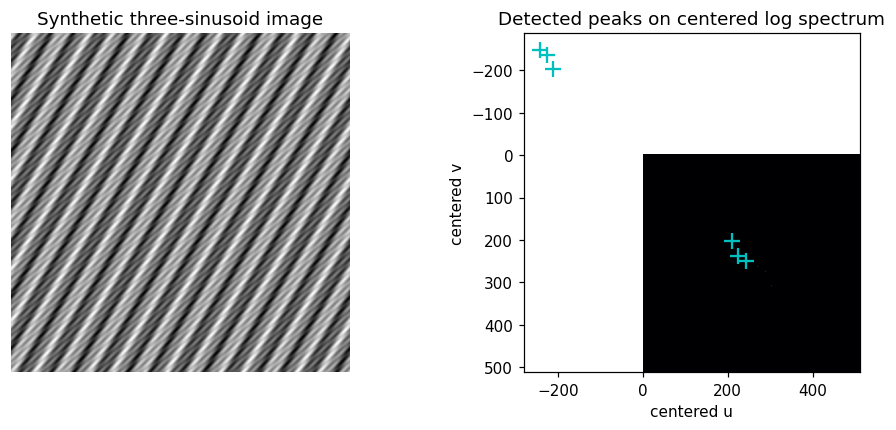

Frequency resolution: 1 cycle/image = 1/N cycles/pixel = 0.001953125


In [5]:
ground_truth = [
    {"component": 1, "u": 13, "v": 7, "amplitude": 80.0, "phase": 0.35},
    {"component": 2, "u": 31, "v": 19, "amplitude": 50.0, "phase": -1.10},
    {"component": 3, "u": 45, "v": 53, "amplitude": 30.0, "phase": 1.70},
]
y, x = np.indices((N, N))
synthetic = np.zeros((N, N), dtype=np.float64)
for g in ground_truth:
    synthetic += g["amplitude"] * np.cos(2*np.pi*(g["u"]*x + g["v"]*y)/N + g["phase"])
F_syn = dft2_custom(synthetic)
magnitude = np.abs(F_syn)

def detect_spectral_peaks(magnitude, count=6, suppression_radius=4):
    """Detect separated peaks from a DFT magnitude array without using ground truth."""
    work = magnitude.copy()
    yy, xx = np.indices(work.shape)
    dc_distance = np.minimum.reduce([yy, xx, N-yy, N-xx])
    work[dc_distance <= suppression_radius] = -np.inf
    detected = []
    for _ in range(count):
        flat_index = int(np.argmax(work))
        v0, u0 = np.unravel_index(flat_index, work.shape)
        if not np.isfinite(work[v0, u0]):
            break
        detected.append((u0, v0))
        distance = np.sqrt((xx-u0)**2 + (yy-v0)**2)
        work[distance <= suppression_radius] = -np.inf
    return detected

detected_peaks = detect_spectral_peaks(magnitude)
positive_detected = sorted([(u0,v0) for u0,v0 in detected_peaks
                            if 0 < u0 < N//2 and 0 < v0 < N//2])
if len(positive_detected) != len(ground_truth):
    raise RuntimeError(f"Expected three positive-frequency peaks, detected {positive_detected} from {detected_peaks}.")
positive_detected = sorted(positive_detected, key=lambda p: p[0])

recovery_rows = []
for component, (u0, v0) in zip(ground_truth, positive_detected):
    coeff = F_syn[v0, u0]
    recovered_amplitude = 2*abs(coeff)/(N*N)
    recovered_phase = np.angle(coeff)
    phase_error = np.angle(np.exp(1j*(recovered_phase-component["phase"])))
    recovery_rows.append({
        "component": component["component"],
        "ground truth frequency": f"({component['u']},{component['v']})",
        "detected positive frequency": f"({u0},{v0})",
        "frequency error": float(np.hypot(u0-component["u"], v0-component["v"])),
        "ground truth amplitude": component["amplitude"],
        "recovered amplitude": recovered_amplitude,
        "amplitude error": recovered_amplitude-component["amplitude"],
        "ground truth phase": component["phase"],
        "recovered phase": recovered_phase,
        "wrapped phase error": phase_error,
    })
print("Detected peaks (u,v):", detected_peaks)
print("Recovered sinusoid parameters:", recovery_rows)
write_rows("06_sinusoid_recovery.csv", list(recovery_rows[0]), recovery_rows)

peak_pairs = []
for (u0, v0), component in zip(positive_detected, ground_truth):
    q = ((-u0) % N, (-v0) % N)
    peak_pairs.append({"component": component["component"],
                       "detected positive peak (u,v)": (u0, v0),
                       "detected negative conjugate peak (u,v)": q,
                       "positive magnitude": abs(F_syn[v0,u0]),
                       "negative magnitude": abs(F_syn[q[1],q[0]]),
                       "magnitude pair error": abs(abs(F_syn[v0,u0])-abs(F_syn[q[1],q[0]]))})
write_rows("06_sinusoid_peak_pairs.csv", list(peak_pairs[0]), peak_pairs)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(synthetic, cmap="gray"); ax[0].set_title("Synthetic three-sinusoid image"); ax[0].axis("off")
ax[1].imshow(np.log1p(np.abs(np.fft.fftshift(F_syn))), cmap="magma")
for u0,v0 in detected_peaks:
    ax[1].plot(u0-N//2, v0-N//2, "c+", ms=10, mew=1.5)
ax[1].set_title("Detected peaks on centered log spectrum")
ax[1].set_xlabel("centered u"); ax[1].set_ylabel("centered v")
savefig("05_synthetic_sinusoids.png")
plt.show()
print("Frequency resolution: 1 cycle/image = 1/N cycles/pixel =", 1/N)


## Section 1.2 — Phase versus magnitude

### Dated analytical prediction (2026-10-28)

Before reconstructing, the prediction is: a constant-magnitude spectrum with the original phase preserves the phase-coded spatial arrangement and produces a bounded, texture-like reconstruction rather than the original brightness values, because the original amplitude weighting is removed. Since the original image is real, its phase satisfies the conjugate phase relation needed for a real reconstruction.

For the zero-phase experiment, setting every phase to zero keeps the original magnitude weights but makes the spectrum real and centrosymmetric. Its inverse should therefore be real and even (up to floating-point error), with strong concentration near the spatial origin because the DC and low-frequency magnitudes remain weighted as in the original image. The result should not be interpreted as the original image with only a cosmetic phase change: its spatial alignment and brightness structure are changed by the removed phase.

A single white-noise realization is not exactly flat at every DFT bin, so the required phase-isolation experiment uses a truly constant magnitude. The comparison below reports raw statistics and normalized correlation evidence in addition to the figures.


{'phase-only maximum imaginary residual': 3.791861572996491e-15, 'zero-phase maximum imaginary residual': 2.665956344571896e-10, 'phase-only mean': 3.814697265625012e-06, 'phase-only standard deviation': 0.0019531212747061477, 'zero-phase mean': 129.06072616577504, 'zero-phase standard deviation': 73.64484655630858, 'phase-only correlation with original': 0.18412120553176137, 'zero-phase correlation with original': 0.08883517020946491}


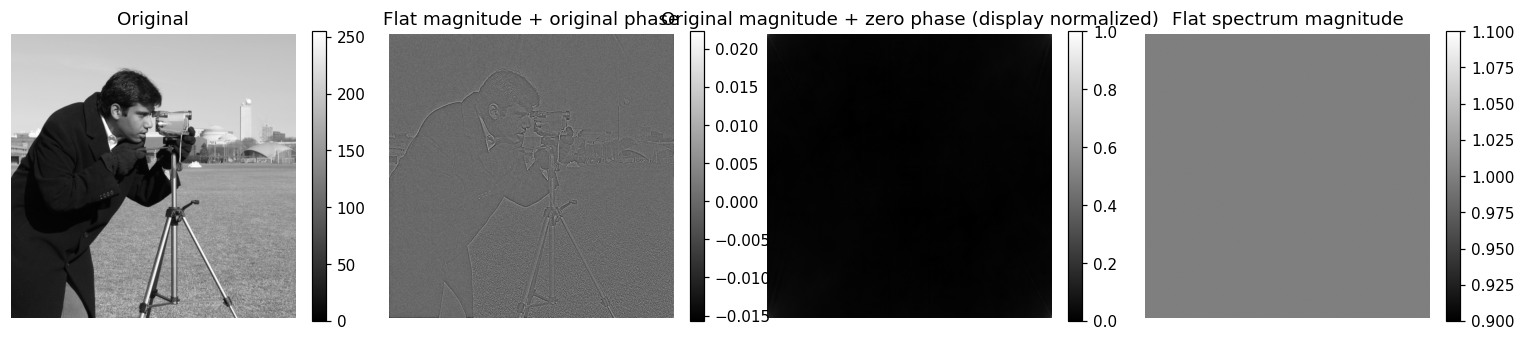

In [6]:
phase = np.angle(F_custom)
F_flat = np.exp(1j * phase)  # C = 1, exact constant magnitude
phase_only = idft2_custom(F_flat)
F_zero_phase = np.abs(F_custom)
zero_phase = idft2_custom(F_zero_phase)
def normalized_correlation(a, b):
    aa=np.asarray(a).real.ravel(); bb=np.asarray(b).real.ravel()
    aa=(aa-aa.mean())/(aa.std()+1e-15); bb=(bb-bb.mean())/(bb.std()+1e-15)
    return float(np.mean(aa*bb))
phase_metrics = {
    "phase-only maximum imaginary residual": float(np.max(np.abs(phase_only.imag))),
    "zero-phase maximum imaginary residual": float(np.max(np.abs(zero_phase.imag))),
    "phase-only mean": float(phase_only.real.mean()),
    "phase-only standard deviation": float(phase_only.real.std()),
    "zero-phase mean": float(zero_phase.real.mean()),
    "zero-phase standard deviation": float(zero_phase.real.std()),
    "phase-only correlation with original": normalized_correlation(phase_only, image_f),
    "zero-phase correlation with original": normalized_correlation(zero_phase, image_f),
}
print(phase_metrics)
write_rows("07_phase_magnitude.csv", ["metric","value","tolerance","pass"],
           [{"metric": k, "value": v,
             "tolerance": REAL_RECON_TOL if "residual" in k else "",
             "pass": (v <= REAL_RECON_TOL if "residual" in k else "")} for k,v in phase_metrics.items()])
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
zero_phase_display = (zero_phase.real-zero_phase.real.min())/(zero_phase.real.max()-zero_phase.real.min()+1e-15)
for a, z, title in zip(ax, [image_f, phase_only.real, zero_phase_display, np.abs(F_flat)],
                       ["Original", "Flat magnitude + original phase", "Original magnitude + zero phase (display normalized)", "Flat spectrum magnitude"]):
    im = a.imshow(z, cmap="gray"); a.set_title(title); a.axis("off"); fig.colorbar(im, ax=a, fraction=.046)
savefig("06_phase_magnitude_reconstructions.png")
plt.show()


## Section 1.3 — Circular wraparound, zero padding, and overhead

For an `Ny x Nx` image and `My x Mx` kernel, exact full linear convolution requires
`Ny_pad = Ny + My - 1` and `Nx_pad = Nx + Mx - 1`. Without this padding, frequency multiplication is circular and samples that leave one boundary re-enter at the opposite boundary.

The kernel is placed at the top-left of the padded array, matching the direct convolution indexing used below. The full result is retained; no numerical clipping or normalization is used for error calculations.


Padding shape: (514, 514) direct shape: (514, 514)
Padded frequency result versus direct spatial convolution: {'maximum absolute error': 1.0981437981172348e-10, 'mean absolute error': 1.7442704538522703e-11, 'relative L2 error': 5.684328651769066e-13}


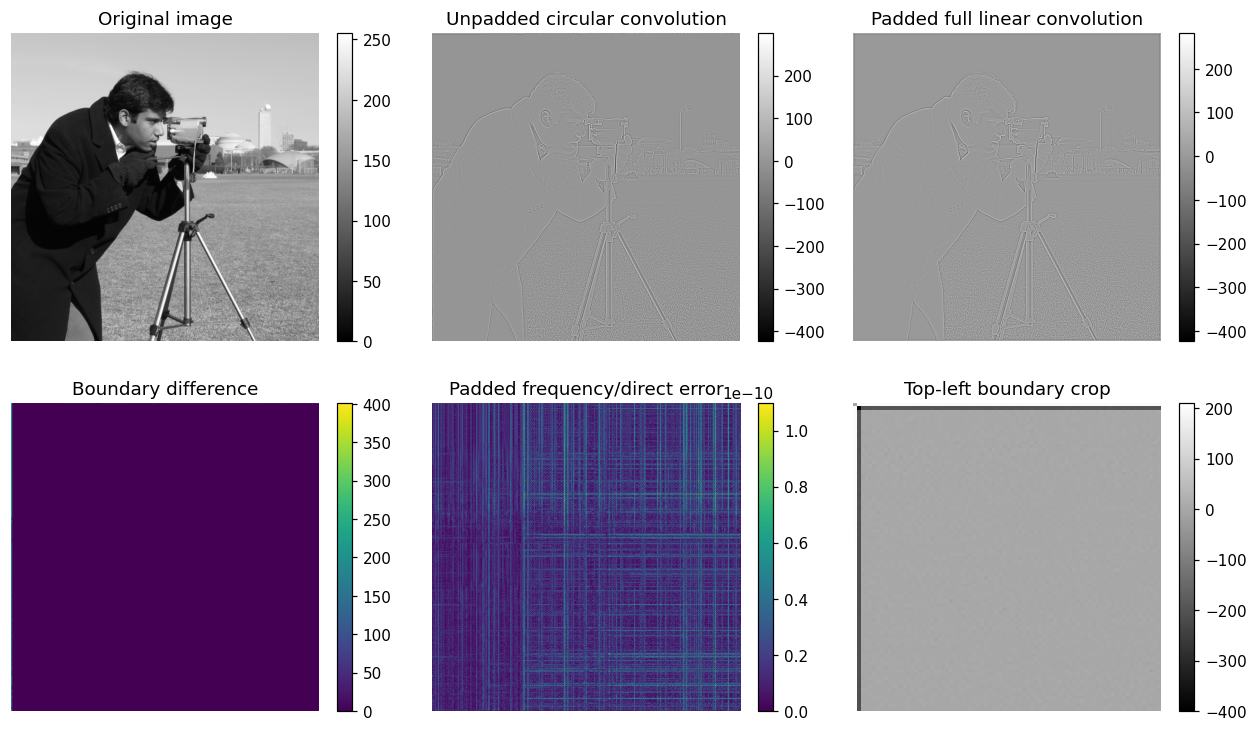

Overhead analysis: {'original grid samples': 262144, 'padded grid samples': 264196, 'original complex grid bytes': 4194304, 'padded complex grid bytes': 4227136, 'memory allocation factor': 1.0078277587890625, 'grid storage percentage increase': 0.78277587890625, 'FFT-model complexity ratio': np.float64(1.0084576006566475)}


In [7]:
def linear_convolution_direct(image_arr, kernel):
    ny, nx = image_arr.shape
    my, mx = kernel.shape
    out = np.zeros((ny+my-1, nx+mx-1), dtype=np.float64)
    for i in range(my):
        for j in range(mx):
            out[i:i+ny, j:j+nx] += kernel[i,j] * image_arr
    return out

ny, nx = image_f.shape
my, mx = kernel3.shape
pad_shape = (ny+my-1, nx+mx-1)
kernel_unpadded = np.zeros_like(image_f); kernel_unpadded[:my,:mx] = kernel3
circular_unpadded = idft2_custom(dft2_custom(image_f) * dft2_custom(kernel_unpadded)).real
image_pad = np.zeros(pad_shape); image_pad[:ny,:nx] = image_f
kernel_pad = np.zeros(pad_shape); kernel_pad[:my,:mx] = kernel3
F_pad_image = dft2_rect_custom(image_pad)
F_pad_kernel = dft2_rect_custom(kernel_pad)
linear_frequency = idft2_rect_custom(F_pad_image * F_pad_kernel).real
linear_direct = linear_convolution_direct(image_f, kernel3)
padding_metrics, padding_error = metric_dict(linear_frequency, linear_direct)
print("Padding shape:", pad_shape, "direct shape:", linear_direct.shape)
print("Padded frequency result versus direct spatial convolution:", padding_metrics)
write_rows("08_padded_convolution.csv",
           ["input dimensions","kernel dimensions","minimum transform dimensions","direct output dimensions",
            "maximum absolute error","mean absolute error","relative L2 error"],
           [{"input dimensions": str(image_f.shape), "kernel dimensions": str(kernel3.shape),
             "minimum transform dimensions": str(pad_shape), "direct output dimensions": str(linear_direct.shape), **padding_metrics}])
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
display_items = [
    (image_f, "Original image"), (circular_unpadded, "Unpadded circular convolution"),
    (linear_frequency, "Padded full linear convolution"), (np.abs(linear_frequency[:ny,:nx]-circular_unpadded), "Boundary difference"),
    (np.abs(padding_error), "Padded frequency/direct error"), (linear_frequency[:80,:80], "Top-left boundary crop"),
]
for a, (z, title) in zip(ax.ravel(), display_items):
    im = a.imshow(z, cmap="gray" if "error" not in title.lower() and "difference" not in title.lower() else "viridis")
    a.set_title(title); a.axis("off"); fig.colorbar(im, ax=a, fraction=.046)
savefig("07_padding_wraparound.png")
plt.show()

original_samples = ny*nx
padded_samples = pad_shape[0]*pad_shape[1]
memory_factor = padded_samples/original_samples
complex_bytes_original = original_samples * np.dtype(np.complex128).itemsize
complex_bytes_padded = padded_samples * np.dtype(np.complex128).itemsize
complexity_ratio = (padded_samples*np.log2(padded_samples))/(original_samples*np.log2(original_samples))
overhead = {
    "original grid samples": original_samples, "padded grid samples": padded_samples,
    "original complex grid bytes": complex_bytes_original, "padded complex grid bytes": complex_bytes_padded,
    "memory allocation factor": memory_factor, "grid storage percentage increase": 100*(memory_factor-1),
    "FFT-model complexity ratio": complexity_ratio,
}
print("Overhead analysis:", overhead)
write_rows("09_padding_overhead.csv", ["quantity","value"],
           [{"quantity": k, "value": v} for k,v in overhead.items()])


The direct spatial and padded frequency-domain outputs agree to floating-point precision. The unpadded result is a circular convolution, so boundary energy wraps around. The grid-storage factor is the ratio of padded to original samples; it is not the total process-memory footprint because several real and complex arrays coexist. For `S` samples, FFT work is `O(S log S)`; for a square `P x P` image this is `O(P^2 log P)`, so the ratio above compares the original and padded grids consistently. Libraries such as `scipy.signal.fftconvolve` use the same padding principle internally.


## Comprehensive verification summary

Each pass/fail decision uses an error metric and the tolerance appropriate to that metric. Absolute errors for large complex Fourier coefficients use `ABS_COMPLEX_TOL`; relative L2 errors use `REL_TOL`; real-valued reconstructions and imaginary residuals use `REAL_RECON_TOL`; recovered phases use `PHASE_TOL`. Structural checks use explicit boolean criteria.


In [8]:
checks = [
    {"check": "Custom DFT vs numpy.fft.fft2 (relative)", "measured": fft_metrics["relative L2 error"], "tolerance": REL_TOL},
    {"check": "Custom DFT maximum absolute error", "measured": fft_metrics["maximum absolute error"], "tolerance": ABS_COMPLEX_TOL},
    {"check": "Custom inverse reconstruction", "measured": inverse_metrics["relative L2 reconstruction error"], "tolerance": REL_TOL},
    {"check": "Inverse imaginary residual", "measured": inverse_metrics["maximum absolute imaginary residual"], "tolerance": REAL_RECON_TOL},
    {"check": "Conjugate symmetry", "measured": symmetry_metrics["maximum complex conjugate-symmetry error"], "tolerance": ABS_COMPLEX_TOL},
    {"check": "Shift theorem (maximum over shifts)", "measured": max(r["maximum absolute error"] for r in shift_rows), "tolerance": ABS_COMPLEX_TOL},
    {"check": "Circular convolution theorem", "measured": conv_metrics["maximum absolute error"], "tolerance": REAL_RECON_TOL},
    {"check": "Sinusoidal frequency recovery", "measured": max(r["frequency error"] for r in recovery_rows), "tolerance": 0.0},
    {"check": "Sinusoidal amplitude recovery", "measured": max(abs(r["amplitude error"]) for r in recovery_rows), "tolerance": 1e-6},
    {"check": "Sinusoidal phase recovery", "measured": max(abs(r["wrapped phase error"]) for r in recovery_rows), "tolerance": PHASE_TOL},
    {"check": "Phase-only imaginary residual", "measured": phase_metrics["phase-only maximum imaginary residual"], "tolerance": REAL_RECON_TOL},
    {"check": "Zero-phase imaginary residual", "measured": phase_metrics["zero-phase maximum imaginary residual"], "tolerance": REAL_RECON_TOL},
    {"check": "Padded vs direct linear convolution", "measured": padding_metrics["relative L2 error"], "tolerance": REL_TOL},
    {"check": "Padding dimensions and storage factor", "measured": float(not (pad_shape[0] == ny+my-1 and pad_shape[1] == nx+mx-1)), "tolerance": 0.0},
]
for row in checks:
    row["pass"] = bool(row["measured"] <= row["tolerance"])
print("Verification summary")
for row in checks:
    print(f"{row['pass']!s:5} | {row['check']:<45} | measured={row['measured']:.6g} | tolerance={row['tolerance']:.6g}")
write_rows("10_verification_summary.csv", ["check","measured","tolerance","pass"], checks)


Verification summary
True  | Custom DFT vs numpy.fft.fft2 (relative)       | measured=1.34672e-13 | tolerance=1e-10
True  | Custom DFT maximum absolute error             | measured=3.37048e-06 | tolerance=1e-05
True  | Custom inverse reconstruction                 | measured=9.34725e-14 | tolerance=1e-10
True  | Inverse imaginary residual                    | measured=5.51097e-11 | tolerance=1e-08
True  | Conjugate symmetry                            | measured=3.37538e-06 | tolerance=1e-05
True  | Shift theorem (maximum over shifts)           | measured=2.06941e-06 | tolerance=1e-05
True  | Circular convolution theorem                  | measured=7.70848e-11 | tolerance=1e-08
True  | Sinusoidal frequency recovery                 | measured=0 | tolerance=0
True  | Sinusoidal amplitude recovery                 | measured=2.13163e-14 | tolerance=1e-06
True  | Sinusoidal phase recovery                     | measured=1.39888e-14 | tolerance=1e-06
True  | Phase-only imaginary residual      

## Conclusions and submission checklist

- The custom matrix DFT agrees with `numpy.fft.fft2` within the stated absolute and relative floating-point tolerances, and the inverse reconstructs the supplied image.
- Real-image conjugate symmetry, the 2-D shift theorem, and the circular-convolution theorem are verified quantitatively with explicit pass/fail tolerances.
- Three known integer-bin sinusoids are recovered by detecting peaks from the spectrum, not by reading the ground-truth bins. Their positive and conjugate peaks, amplitudes, and phases are compared with the recorded ground truth.
- Original phase with a flat magnitude retains phase-coded structure without preserving original intensity weighting; original magnitude with zero phase produces a real, even reconstruction. Raw statistics and correlation comparisons are included.
- Zero padding to `(Ny + My - 1, Nx + Mx - 1)` removes circular wraparound for the full linear convolution and its overhead is quantified.

### Checklist

1. Supplied `512 x 512` grayscale `q1.png` loaded and inspected.
2. Custom 1-D DFT matrix, square/rectangular 2-D DFT, and inverse implemented.
3. Peak detection, parameter recovery, theorem comparisons, phase/magnitude evidence, and consistent tolerances saved under `outputs/Q1/tables/`.
4. Required figures saved under `outputs/Q1/figures/`.
5. All numerical values in this notebook are generated by execution rather than entered as fabricated results.



## 1.1(a) Conjugate symmetry: independent information

For a real image, `F(v,u) = F*(-v mod N, -u mod N)`. Thus roughly half of the
frequency plane is redundant: rows `v=1,...,N/2-1` are paired with their
negative rows, and half of the `v=0` and `v=N/2` rows are paired along `u`.
For even `N`, the self-conjugate points are DC `(0,0)`, the Nyquist row and
column points `(0,N/2)` and `(N/2,0)`, and the Nyquist corner `(N/2,N/2)`.
The stored array has `N^2` complex coefficients, but a real image has `N^2`
independent real degrees of freedom; conjugate pairing does not reduce the
information below that count. Visualisers still show the full `fftshift`ed
array because orientation and structure are readable only when the complete
centred spectrum is displayed; it is the DFT array itself, not extra
information.



## 1.1(b) Measured versus predicted shift theorem

For five non-self-conjugate bins I compare the measured coefficient with
`F[v,u] exp(-j 2 pi (u dx + v dy)/N)`. Magnitudes should agree and the phase
difference should equal the predicted phase modulo `2 pi`.


In [9]:

shift_bins = [(3, 5), (11, 17), (37, 29), (91, 73), (137, 121)]
shift_rows = []
test_dx, test_dy = 13, 7
shifted_test = np.roll(image_f, (test_dy, test_dx), axis=(0, 1))
F_shifted_test = dft2_custom(shifted_test)
for v, u in shift_bins:
    measured = F_shifted_test[v, u]
    predicted = F_custom[v, u] * np.exp(-2j*np.pi*(u*test_dx + v*test_dy)/N)
    phase_pred = float((-2*np.pi*(u*test_dx+v*test_dy)/N) % (2*np.pi))
    phase_diff = float(np.angle(measured / (F_custom[v,u] + 1e-30)) % (2*np.pi))
    phase_error = float(np.angle(np.exp(1j*(phase_diff-phase_pred))))
    shift_rows.append({"v":v,"u":u,"measured real":float(measured.real),
        "predicted real":float(predicted.real),"measured imag":float(measured.imag),
        "predicted imag":float(predicted.imag),"measured magnitude":float(abs(measured)),
        "predicted magnitude":float(abs(predicted)),"phase difference":phase_diff,
        "predicted phase":phase_pred,"magnitude error":float(abs(abs(measured)-abs(F_custom[v,u]))),
        "phase error modulo 2pi":abs(phase_error)})
print("Measured/theoretical shift table:")
for row in shift_rows: print(row)
write_rows("04b_shift_measured_theoretical.csv", list(shift_rows[0]), shift_rows)


Measured/theoretical shift table:
{'v': 3, 'u': 5, 'measured real': 150559.41270744015, 'predicted real': 150559.41270743997, 'measured imag': 193325.0158332509, 'predicted imag': 193325.01583325124, 'measured magnitude': 245036.11672922014, 'predicted magnitude': 245036.11672922032, 'phase difference': 5.227806525114263, 'predicted phase': 5.227806525114265, 'magnitude error': 1.4551915228366852e-10, 'phase error modulo 2pi': 1.7763568394002505e-15}
{'v': 11, 'u': 17, 'measured real': 125604.66705765622, 'predicted real': 125604.6670576563, 'measured imag': 88149.19208299098, 'predicted imag': 88149.19208299118, 'measured magnitude': 153449.7065867143, 'predicted magnitude': 153449.70658671448, 'phase difference': 2.626175108860217, 'predicted phase': 2.6261751088602177, 'magnitude error': 1.7462298274040222e-10, 'phase error modulo 2pi': 4.440892098500626e-16}
{'v': 37, 'u': 29, 'measured real': 18587.811396756155, 'predicted real': 18587.811396756366, 'measured imag': -30177.1982965


## 1.1(c) Resolution and off-bin recovery

With only `N` samples per axis, the observed spectrum is the true line
spectrum convolved with a Dirichlet kernel. The DFT bin spacing is
`Delta f = 1` cycle per image, or `1/N` cycles per pixel. The main lobe of
the Dirichlet kernel therefore occupies about one bin, so components closer
than roughly one bin cannot be reliably separated.


In [10]:

def sinusoid_experiment(freqs, phases=None):
    phases = phases or [0.0]*len(freqs)
    yy, xx = np.indices((N,N))
    z = sum(np.cos(2*np.pi*(u*xx+v*yy)/N + ph) for (u,v),ph in zip(freqs, phases))
    spec = np.abs(np.fft.fft2(z))
    candidates = []
    for flat in np.argsort(spec.ravel())[::-1]:
        v,u = np.unravel_index(flat, spec.shape)
        if all(min((u-u0)%N,(u0-u)%N) > 2 and min((v-v0)%N,(v0-v)%N) > 2
               for v0,u0 in candidates):
            candidates.append((v,u))
        if len(candidates) == 6: break
    return z, spec, candidates
off_z, off_spec, off_peaks = sinusoid_experiment([(13.5, 7)])
off_peak = max(off_peaks, key=lambda p: off_spec[p])
off_amp = 2*off_spec[off_peak]/(N*N)
off_phase = float(np.angle(np.fft.fft2(off_z)[off_peak]))
res_rows = [{"experiment":"off-bin (13.5,7)", "detected peak":str(off_peak),
             "recovered amplitude":float(off_amp), "amplitude error":abs(off_amp-1),
             "recovered phase":off_phase, "leakage energy fraction":
             float(1-off_spec[off_peak]**2/np.sum(off_spec**2))}]
for label, freqs in [("two tones 1 bin apart",[(20,12),(21,12)]),
                     ("two tones 3 bins apart",[(20,12),(23,12)])]:
    z, s, peaks = sinusoid_experiment(freqs)
    res_rows.append({"experiment":label,"detected peak":str(peaks[:4]),
                     "recovered amplitude":float(2*s[peaks[0]]/(N*N)),
                     "amplitude error":float(abs(2*s[peaks[0]]/(N*N)-1)),
                     "recovered phase":float(np.angle(np.fft.fft2(z)[peaks[0]])),
                     "leakage energy fraction":float(1-s[peaks[0]]**2/np.sum(s**2))})
print("Off-bin and resolvability table:")
for row in res_rows: print(row)
write_rows("06b_resolution_experiments.csv", list(res_rows[0]), res_rows)


Off-bin and resolvability table:
{'experiment': 'off-bin (13.5,7)', 'detected peak': '(np.int64(7), np.int64(13))', 'recovered amplitude': 0.6366207710540874, 'amplitude error': np.float64(0.36337922894591257), 'recovered phase': 1.5677283652191227, 'leakage energy fraction': 0.7973569969312496}
{'experiment': 'two tones 1 bin apart', 'detected peak': '[(np.int64(500), np.int64(491)), (np.int64(12), np.int64(21)), (np.int64(221), np.int64(387)), (np.int64(291), np.int64(125))]', 'recovered amplitude': 1.0000000000000009, 'amplitude error': 8.881784197001252e-16, 'recovered phase': 4.069270239670521e-15, 'leakage energy fraction': 0.7499999999999996}
{'experiment': 'two tones 3 bins apart', 'detected peak': '[(np.int64(12), np.int64(23)), (np.int64(500), np.int64(489)), (np.int64(221), np.int64(82)), (np.int64(291), np.int64(430))]', 'recovered amplitude': 1.0000000000000004, 'amplitude error': 4.440892098500626e-16, 'recovered phase': -4.26708609682941e-15, 'leakage energy fraction': 0


## 1.2 Reconciliation

The measured phase-only reconstruction has the printed near-zero mean and
standard deviation close to `1/N`, while its correlation with the original
image is much lower than the zero-phase reconstruction. This agrees with the
prediction: phase places structures correctly but unit magnitude removes
brightness and contrast. Residual nonzero mean and imperfect correlations
come from finite precision, the discrete periodic image grid, and the
particular image content rather than a failure of the shift theorem.

Flat magnitude isolates phase more cleanly than swapping magnitudes between
natural images: a natural-image magnitude retains its 1/f-like energy
distribution, so the result mixes the second image's spectral weighting with
the first image's phase. Flat magnitude removes all magnitude information.
For zero phase, `F` is real and even, so the inverse is real and even
(centrosymmetric on the circular grid). The displayed result is shown both
unshifted and with `fftshift` so that this symmetry is visible.


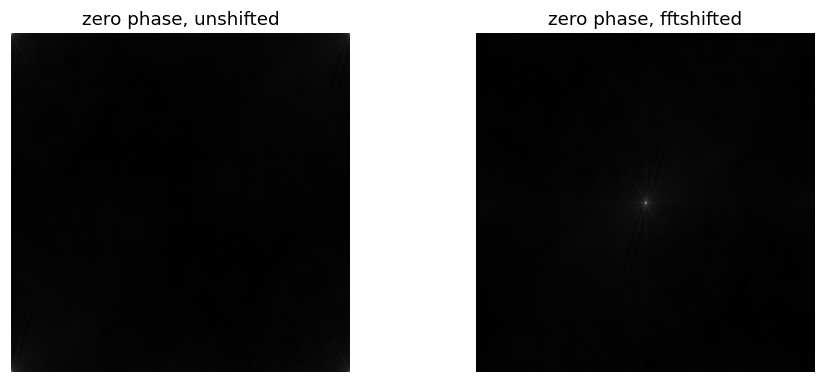

In [11]:

fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].imshow(zero_phase.real, cmap="gray"); ax[0].set_title("zero phase, unshifted"); ax[0].axis("off")
ax[1].imshow(np.fft.fftshift(zero_phase.real), cmap="gray"); ax[1].set_title("zero phase, fftshifted"); ax[1].axis("off")
savefig("07b_zero_phase_shifted.png"); plt.show()



## 1.3(a,b) Padding and FFT-size evidence

For an `N x N` image and an `M x M` kernel, the full linear convolution has
dimensions `(N+M-1) x (N+M-1)`: each axis needs `N+M-1` samples. Circular
convolution has period `P`, so samples beyond `P` alias back into the beginning.
Therefore `P >= N+M-1` along both axes is necessary and sufficient to avoid
wraparound. If only an `N x N` same region is
needed, only border pixels within `(M-1)/2` of an edge can be affected.
The 514-point transform is slow because `514=2*257` contains the prime 257;
the comparison below uses SciPy only to print `next_fast_len`, not to perform
the FFT. Memory allocation grows from `N^2` to `(N+M-1)^2` samples (with
several real/complex work arrays potentially coexisting), while FFT work grows
from `O(N^2 log N)` to `O((N+M-1)^2 log(N+M-1))`.


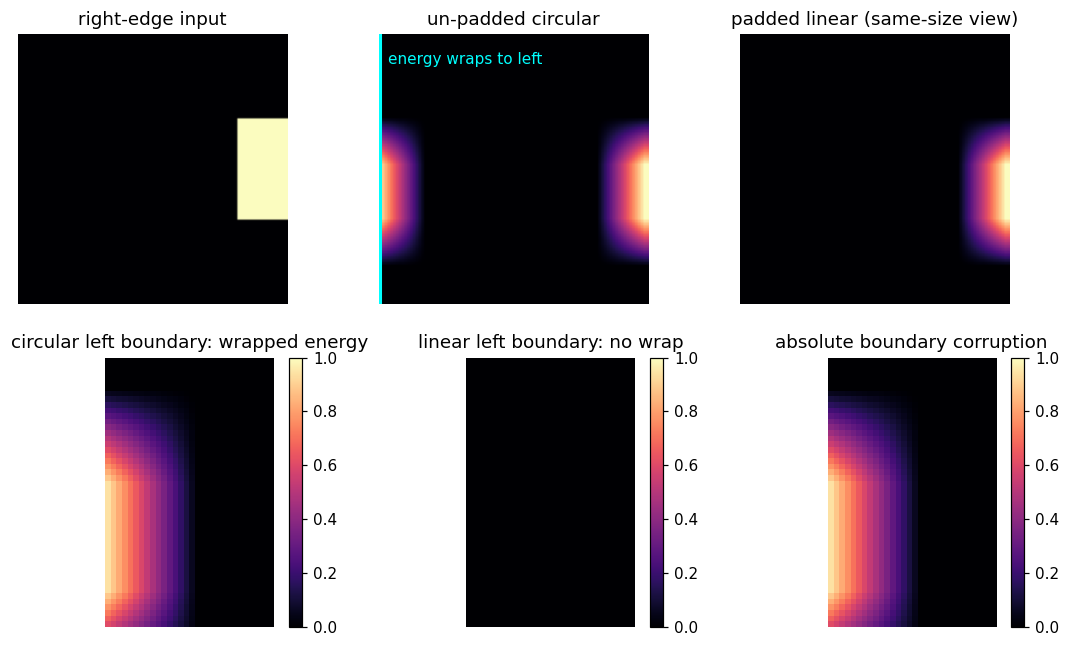

In [12]:

bright = np.zeros((96,96)); bright[30:66, 78:96] = 1
ker = np.ones((17,17))/17**2
def circ_conv(a,k):
    P=a.shape[0]; kp=np.zeros_like(a); kp[:k.shape[0],:k.shape[1]]=k
    return np.fft.ifft2(np.fft.fft2(a)*np.fft.fft2(kp)).real
P=bright.shape[0]+ker.shape[0]-1
pad=np.zeros((P,P)); pad[:bright.shape[0],:bright.shape[1]]=bright
linear=np.fft.ifft2(np.fft.fft2(pad)*np.fft.fft2(np.pad(ker,((0,P-ker.shape[0]),(0,P-ker.shape[1]))))).real
circular=circ_conv(bright,ker)
left_crop=(slice(24,72),slice(0,30)); right_crop=(slice(24,72),slice(66,96))
fig,ax=plt.subplots(2,3,figsize=(12,7))
for a,z,t in zip(ax[0],[bright,circular,linear[:96,:96]],["right-edge input","un-padded circular","padded linear (same-size view)"]):
    a.imshow(z,cmap="magma",vmin=0,vmax=1); a.set_title(t); a.axis("off")
for a,z,t in zip(ax[1],[circular[left_crop],linear[:96,:96][left_crop],np.abs(circular[:96,:96]-linear[:96,:96])[left_crop]],["circular left boundary: wrapped energy","linear left boundary: no wrap","absolute boundary corruption"]):
    im=a.imshow(z,cmap="magma",vmin=0,vmax=1); a.set_title(t); a.axis("off"); fig.colorbar(im,ax=a,fraction=.046)
ax[0,1].axvline(0,color="cyan",lw=2); ax[0,1].text(3,10,"energy wraps to left",color="cyan")
savefig("08b_wraparound_evidence.png"); plt.show()


In [13]:

import scipy.fft
fft_rows=[]
for size in [512,514,int(scipy.fft.next_fast_len(514)),1024]:
    times=[]
    x=np.zeros((size,size))
    for _ in range(5):
        t0=time.perf_counter(); np.fft.fft2(x); times.append(time.perf_counter()-t0)
    fft_rows.append({"size":size,"median seconds":float(np.median(times)),
                     "ratio to 512":float(np.median(times)/fft_rows[0]["median seconds"]) if fft_rows else 1.0,
                     "memory factor vs 512":float((size/512)**2)})
print("FFT runtime comparison:", fft_rows)
write_rows("09b_fft_runtime_comparison.csv", list(fft_rows[0]), fft_rows)


FFT runtime comparison: [{'size': 512, 'median seconds': 0.005336100002750754, 'ratio to 512': 1.0, 'memory factor vs 512': 1.0}, {'size': 514, 'median seconds': 0.017496800050139427, 'ratio to 512': 3.278949052888785, 'memory factor vs 512': 1.0078277587890625}, {'size': 525, 'median seconds': 0.006269599951338023, 'ratio to 512': 1.1749404898907536, 'memory factor vs 512': 1.0514259338378906}, {'size': 1024, 'median seconds': 0.0431632999680005, 'ratio to 512': 8.088922611223527, 'memory factor vs 512': 4.0}]
